# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [ ]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

[모집단] 고객 10,000명 · 모평균 μ = 7.481 · 모표준편차 σ = 1.181

[1] 표본 1개 (n=30) 평균 = 7.326  → 모평균과 차이 -0.155

[2] 같은 방법으로 5번 뽑으면
    표본 1: 평균 = 7.170   (모평균과 차이 -0.311)
    표본 2: 평균 = 7.122   (모평균과 차이 -0.359)
    표본 3: 평균 = 7.196   (모평균과 차이 -0.285)
    표본 4: 평균 = 7.032   (모평균과 차이 -0.449)
    표본 5: 평균 = 7.562   (모평균과 차이 +0.082)

[3] 표본 1,000개의 평균들
    표본평균들의 평균     = 7.488   (모평균 7.481과 거의 같음)
    표본평균들의 표준편차 = 0.211   (이론 표준오차 σ/√n = 0.216)
    표본평균의 95%가 들어온 범위: 7.08 ~ 7.90

[4] 표본 크기별 표본평균의 흔들림
    n= 10: 표준편차 0.382  (이론 σ/√n = 0.374)
    n= 30: 표준편차 0.211  (이론 σ/√n = 0.216)
    n=100: 표준편차 0.116  (이론 σ/√n = 0.118)


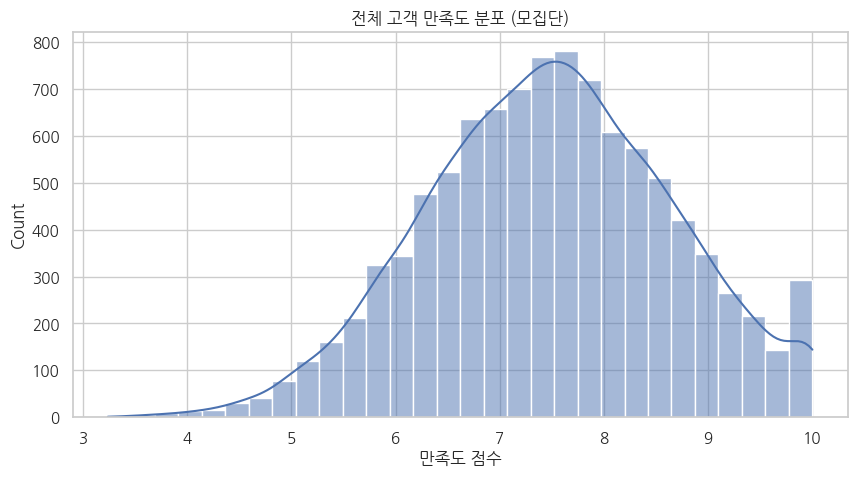

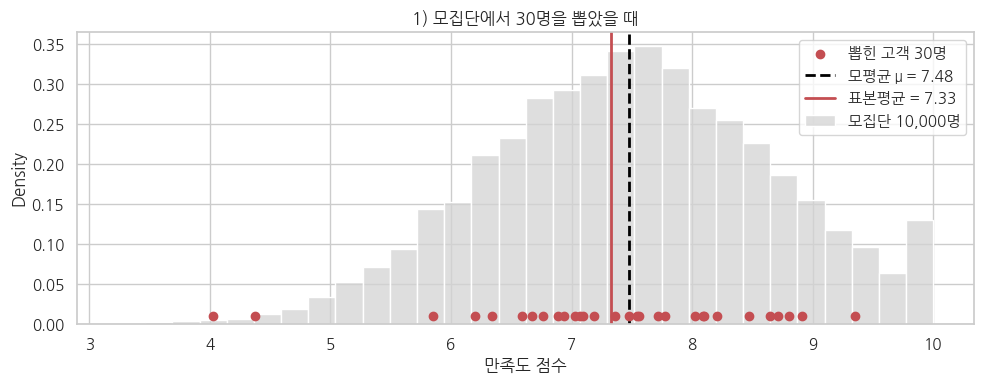

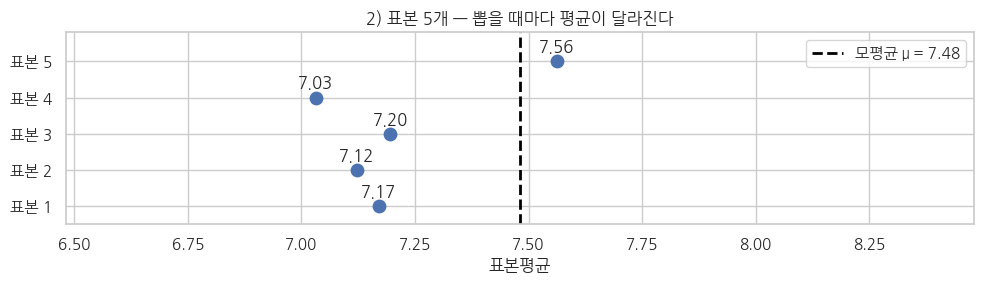

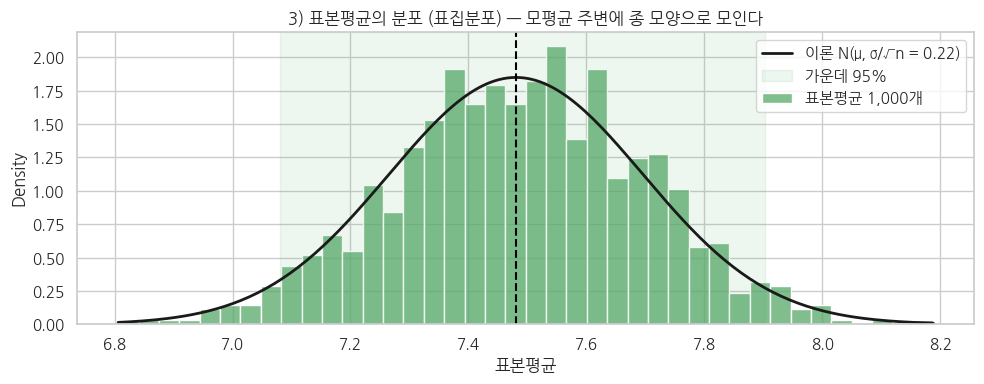

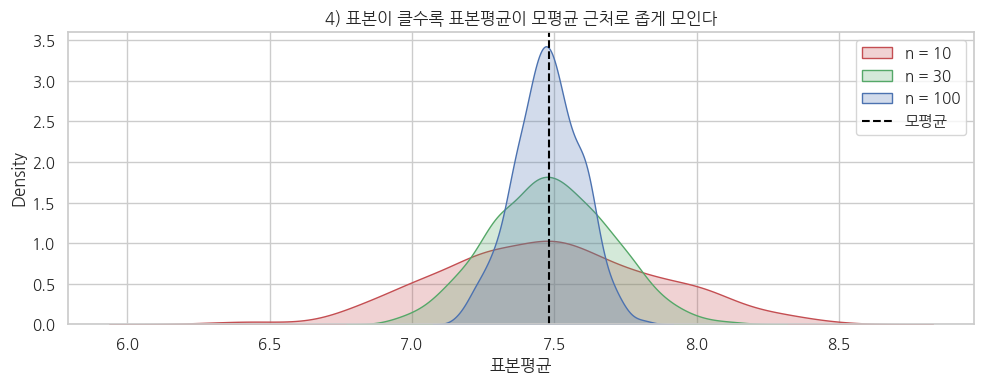

In [2]:
# ═════════════════════════════════════════════
# [실습] 표본 30명으로 전체 고객 만족도 추정하기  — 이 셀 하나로 전부 실행됩니다
# ═════════════════════════════════════════════

# ── 0) 라이브러리 + 한글 폰트 (Colab에서 처음 한 번 설치) ──
import os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
if not os.path.exists(font_path):                       # 나눔고딕이 없으면 설치
    subprocess.run("apt-get -qq install -y fonts-nanum", shell=True)
fm.fontManager.addfont(font_path)                        # 런타임 재시작 없이 바로 등록
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False              # 마이너스(-) 깨짐 방지

# ── 1) 모집단 생성 (전체 고객 만족도 10,000명) ──
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)                  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({"score": population})

sns.histplot(df_pop["score"], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

mu    = df_pop["score"].mean()          # 모평균 (현실에선 모름! 비교용으로만 사용)
sigma = df_pop["score"].std(ddof=0)     # 모표준편차
n     = 30
print(f"[모집단] 고객 {len(df_pop):,}명 · 모평균 μ = {mu:.3f} · 모표준편차 σ = {sigma:.3f}\n")

# ── 2) 표본 1개 뽑기 — 현실에서 실제로 하는 일 ──
sample1 = df_pop["score"].sample(n=n, random_state=1)
x_bar1  = sample1.mean()
print(f"[1] 표본 1개 (n={n}) 평균 = {x_bar1:.3f}  → 모평균과 차이 {x_bar1 - mu:+.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df_pop["score"], bins=30, stat="density", color="lightgray", label="모집단 10,000명", ax=ax)
ax.scatter(sample1, np.full(n, 0.01), color="#C44E52", zorder=3, label=f"뽑힌 고객 {n}명")
ax.axvline(mu, color="black", ls="--", lw=2, label=f"모평균 μ = {mu:.2f}")
ax.axvline(x_bar1, color="#C44E52", lw=2, label=f"표본평균 = {x_bar1:.2f}")
ax.set_title("1) 모집단에서 30명을 뽑았을 때"); ax.set_xlabel("만족도 점수"); ax.legend()
plt.tight_layout(); plt.show()

# ── 3) 표본을 5번 다시 뽑기 — 매번 평균이 다르다! ──
print(f"\n[2] 같은 방법으로 5번 뽑으면")
means5 = []
for i in range(5):
    s = df_pop["score"].sample(n=n, random_state=100 + i)
    means5.append(s.mean())
    print(f"    표본 {i+1}: 평균 = {s.mean():.3f}   (모평균과 차이 {s.mean() - mu:+.3f})")

fig, ax = plt.subplots(figsize=(10, 3))
ax.scatter(means5, range(1, 6), s=80, color="#4C72B0", zorder=3)
for i, m in enumerate(means5, 1):
    ax.text(m, i + 0.25, f"{m:.2f}", ha="center")
ax.axvline(mu, color="black", ls="--", lw=2, label=f"모평균 μ = {mu:.2f}")
ax.set_ylim(0.5, 5.8); ax.set_yticks(range(1, 6)); ax.set_yticklabels([f"표본 {i}" for i in range(1, 6)])
ax.set_xlim(mu - 1, mu + 1); ax.set_title("2) 표본 5개 — 뽑을 때마다 평균이 달라진다")
ax.set_xlabel("표본평균"); ax.legend(); plt.tight_layout(); plt.show()

# ── 4) 1,000번 반복 → 표본평균들의 분포 (표집분포) ──
rng = np.random.default_rng(2025)
pop_arr = df_pop["score"].to_numpy()
means = np.array([rng.choice(pop_arr, n, replace=False).mean() for _ in range(1000)])

se_theory = sigma / np.sqrt(n)          # 표준오차 이론값 σ/√n
lo, hi = np.percentile(means, [2.5, 97.5])
print(f"\n[3] 표본 1,000개의 평균들")
print(f"    표본평균들의 평균     = {means.mean():.3f}   (모평균 {mu:.3f}과 거의 같음)")
print(f"    표본평균들의 표준편차 = {means.std():.3f}   (이론 표준오차 σ/√n = {se_theory:.3f})")
print(f"    표본평균의 95%가 들어온 범위: {lo:.2f} ~ {hi:.2f}")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(means, bins=40, stat="density", color="#55A868", ax=ax, label="표본평균 1,000개")
xs = np.linspace(means.min(), means.max(), 200)
ax.plot(xs, 1/(se_theory*np.sqrt(2*np.pi))*np.exp(-(xs-mu)**2/(2*se_theory**2)),
        "k-", lw=2, label=f"이론 N(μ, σ/√n = {se_theory:.2f})")
ax.axvline(mu, color="black", ls="--")
ax.axvspan(lo, hi, color="#55A868", alpha=.1, label="가운데 95%")
ax.set_title("3) 표본평균의 분포 (표집분포) — 모평균 주변에 종 모양으로 모인다")
ax.set_xlabel("표본평균"); ax.legend(); plt.tight_layout(); plt.show()

# ── 5) 표본 크기를 바꾸면? (n = 10 / 30 / 100) ──
print(f"\n[4] 표본 크기별 표본평균의 흔들림")
fig, ax = plt.subplots(figsize=(10, 4))
for size, c in [(10, "#C44E52"), (30, "#55A868"), (100, "#4C72B0")]:
    m = np.array([rng.choice(pop_arr, size, replace=False).mean() for _ in range(1000)])
    print(f"    n={size:3d}: 표준편차 {m.std():.3f}  (이론 σ/√n = {sigma/np.sqrt(size):.3f})")
    sns.kdeplot(m, ax=ax, color=c, fill=True, alpha=.25, label=f"n = {size}")
ax.axvline(mu, color="black", ls="--", label="모평균")
ax.set_title("4) 표본이 클수록 표본평균이 모평균 근처로 좁게 모인다")
ax.set_xlabel("표본평균"); ax.legend(); plt.tight_layout(); plt.show()

# ▶ 정리
#   - 표본 1개의 평균은 모평균과 '조금' 다르다 → 표본오차(sampling error)
#   - 다시 뽑으면 평균이 또 달라진다 → 표본평균도 하나의 '확률변수'
#   - 표본평균들을 모으면 모평균 주변에 종 모양으로 모인다 (중심극한정리)
#   - 흔들림의 크기 = 표준오차 SE = σ/√n  → n이 4배면 흔들림은 절반
#   - 그래서 표본 평균 하나를 보고할 때는 "7.5점 ± 오차"처럼 불확실성을 함께 말한다 → 신뢰구간

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [3]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
sample = df_pop["score"].sample(n=30, random_state=1)   # 무작위로 30명 추출 (random_state: 결과 재현용)
sample_mean = sample.mean()                              # 표본 평균

print(f"표본 크기   : {len(sample)}명")
print(f"표본 평균   : {sample_mean:.3f}점")
print(f"모평균(참고): {df_pop['score'].mean():.3f}점")     # 현실에선 모르는 값, 비교용
print(f"차이        : {sample_mean - df_pop['score'].mean():+.3f}점")

표본 크기   : 30명
표본 평균   : 7.326점
모평균(참고): 7.481점
차이        : -0.155점


In [4]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
sample_means = []                                          # 표본 평균을 담을 빈 리스트

for i in range(500):
    sample = df_pop["score"].sample(n=30, random_state=i)  # 매번 다른 30명 (i로 재현 가능하게 고정)
    sample_means.append(sample.mean())                     # 평균을 리스트에 추가

print(f"저장된 표본 평균 개수: {len(sample_means)}개")
print(f"처음 5개: {[round(m, 3) for m in sample_means[:5]]}")
print(f"가장 작은 평균: {min(sample_means):.3f}  /  가장 큰 평균: {max(sample_means):.3f}")

저장된 표본 평균 개수: 500개
처음 5개: [np.float64(7.586), np.float64(7.326), np.float64(7.328), np.float64(7.018), np.float64(7.317)]
가장 작은 평균: 6.778  /  가장 큰 평균: 8.113


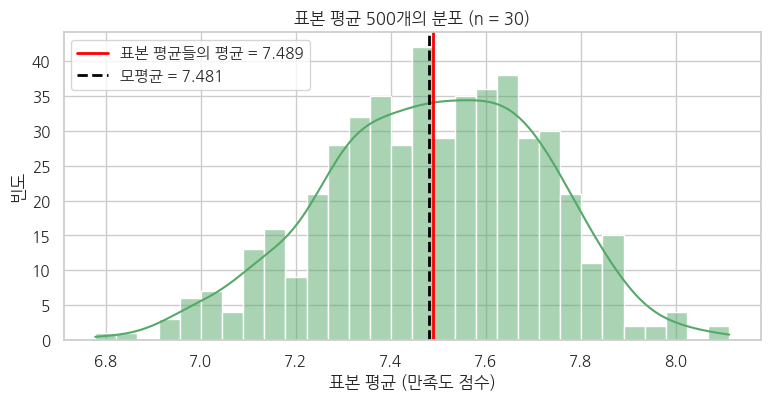

In [5]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
mean_of_means = np.mean(sample_means)        # 표본 평균 500개의 평균
pop_mean      = df_pop["score"].mean()       # 모평균 (비교용)

plt.figure(figsize=(9, 4))
sns.histplot(sample_means, bins=30, kde=True, color="#55A868")
plt.axvline(mean_of_means, color="red", lw=2,
            label=f"표본 평균들의 평균 = {mean_of_means:.3f}")
plt.axvline(pop_mean, color="black", ls="--", lw=2,
            label=f"모평균 = {pop_mean:.3f}")
plt.title("표본 평균 500개의 분포 (n = 30)")
plt.xlabel("표본 평균 (만족도 점수)")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?

■ 질문 1. 표본 평균들의 중심
   표본 평균들의 평균 = 7.489
   모평균             = 7.481
   차이               = +0.009  (0.11%)

■ 질문 2. 1번 vs 500번
   표본 1번의 평균        = 7.586  (모평균과 차이 +0.105)
   500번 평균의 범위      = 6.778 ~ 8.113
   500번 중 가운데 95%    = 7.017 ~ 7.874
   표본 평균의 흔들림(SD) = 0.228

■ 질문 3. 나 vs 친구
   내 표본 평균   = 7.136
   친구 표본 평균 = 7.651
   두 표본에 겹친 고객 수 = 0명 / 30명

■ 질문 4. 분포의 모양
   왜도 = -0.208  /  첨도 = -0.250  (정규면 둘 다 ≈ 0)
   Shapiro-Wilk  W = 0.994,  p = 0.063
   표본 평균들의 SD = 0.228  vs  이론 표준오차 σ/√n = 0.216


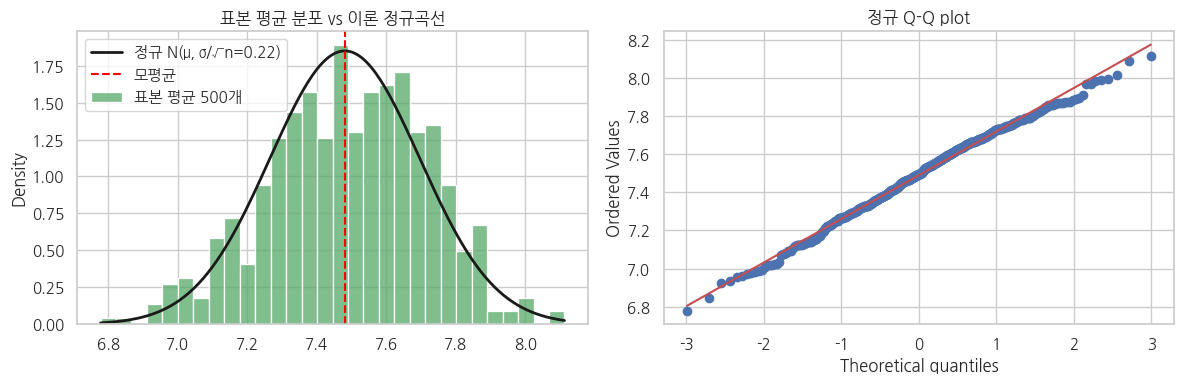

In [6]:
# ─────────────────────────────────────────────
# [문제 1] 🧠 데이터를 어떻게 읽을까요? — 네 질문을 숫자로 확인
#   ※ df_pop, sample_means(Q2) 가 있다고 가정
# ─────────────────────────────────────────────
from scipy import stats

means    = np.array(sample_means)
pop_mean = df_pop["score"].mean()
sigma    = df_pop["score"].std(ddof=0)
n        = 30

# ── 질문 1) 표본 평균들은 어떤 값 주변에? 모평균과 얼마나 비슷한가? ──
print("■ 질문 1. 표본 평균들의 중심")
print(f"   표본 평균들의 평균 = {means.mean():.3f}")
print(f"   모평균             = {pop_mean:.3f}")
print(f"   차이               = {means.mean() - pop_mean:+.3f}  ({abs(means.mean()-pop_mean)/pop_mean:.2%})")
# ▶ 표본 평균들은 모평균 근처에 모인다. 차이는 0.1% 수준 → 표본 평균은 평균적으로 모평균을 정확히 맞힌다(불편추정량).

# ── 질문 2) 1번 뽑을 때 vs 500번 반복할 때 ──
one = means[0]
lo, hi = np.percentile(means, [2.5, 97.5])
print("\n■ 질문 2. 1번 vs 500번")
print(f"   표본 1번의 평균        = {one:.3f}  (모평균과 차이 {one - pop_mean:+.3f})")
print(f"   500번 평균의 범위      = {means.min():.3f} ~ {means.max():.3f}")
print(f"   500번 중 가운데 95%    = {lo:.3f} ~ {hi:.3f}")
print(f"   표본 평균의 흔들림(SD) = {means.std():.3f}")
# ▶ 1번만 뽑으면 '값 하나'만 알 뿐, 그게 얼마나 빗나갔는지 모른다.
#   500번 반복하면 표본 평균이 어디까지 흔들리는지(±약 0.45점 안에 95%) 알 수 있다
#   → 추정값 하나의 '신뢰성'을 숫자로 말할 수 있게 된다. (신뢰구간의 원리)

# ── 질문 3) 친구가 다른 표본을 뽑았다면? ──
me     = df_pop["score"].sample(n=30, random_state=7)
friend = df_pop["score"].sample(n=30, random_state=77)
overlap = len(set(me.index) & set(friend.index))
print("\n■ 질문 3. 나 vs 친구")
print(f"   내 표본 평균   = {me.mean():.3f}")
print(f"   친구 표본 평균 = {friend.mean():.3f}")
print(f"   두 표본에 겹친 고객 수 = {overlap}명 / 30명")
# ▶ 비슷하지만 같지 않다. 무작위로 뽑으면 '누가' 뽑히는지가 매번 달라서
#   점수가 높은 고객이 조금 더 뽑히거나 덜 뽑히는 우연이 생긴다 → 표본오차(sampling error).
#   방법이 틀려서가 아니라, 일부만 보는 한 피할 수 없는 자연스러운 차이다.

# ── 질문 4) 분포 모양은? 정규분포인가? 왜? ──
se_theory = sigma / np.sqrt(n)
W, p = stats.shapiro(means)
print("\n■ 질문 4. 분포의 모양")
print(f"   왜도 = {stats.skew(means):+.3f}  /  첨도 = {stats.kurtosis(means):+.3f}  (정규면 둘 다 ≈ 0)")
print(f"   Shapiro-Wilk  W = {W:.3f},  p = {p:.3f}")
print(f"   표본 평균들의 SD = {means.std():.3f}  vs  이론 표준오차 σ/√n = {se_theory:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(means, bins=30, stat="density", color="#55A868", ax=ax[0], label="표본 평균 500개")
xs = np.linspace(means.min(), means.max(), 200)
ax[0].plot(xs, stats.norm.pdf(xs, pop_mean, se_theory), "k-", lw=2,
           label=f"정규 N(μ, σ/√n={se_theory:.2f})")
ax[0].axvline(pop_mean, color="red", ls="--", label="모평균")
ax[0].set_title("표본 평균 분포 vs 이론 정규곡선"); ax[0].legend()
stats.probplot(means, dist="norm", plot=ax[1]); ax[1].set_title("정규 Q-Q plot")
plt.tight_layout(); plt.show()
# ▶ 종 모양의 정규분포에 가깝다 (왜도·첨도 ≈ 0, Q-Q가 직선, 이론 곡선과 일치).
#   이유: 중심극한정리(CLT) — 평균은 여러 값을 더해 나눈 것이라 극단값들이 서로 상쇄되어
#   모평균 근처 값이 가장 많이 나오고, 멀어질수록 드물어진다.
#   흔들림의 크기도 이론값 σ/√n과 거의 같다 → n이 커질수록 더 좁고 뾰족해진다.

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

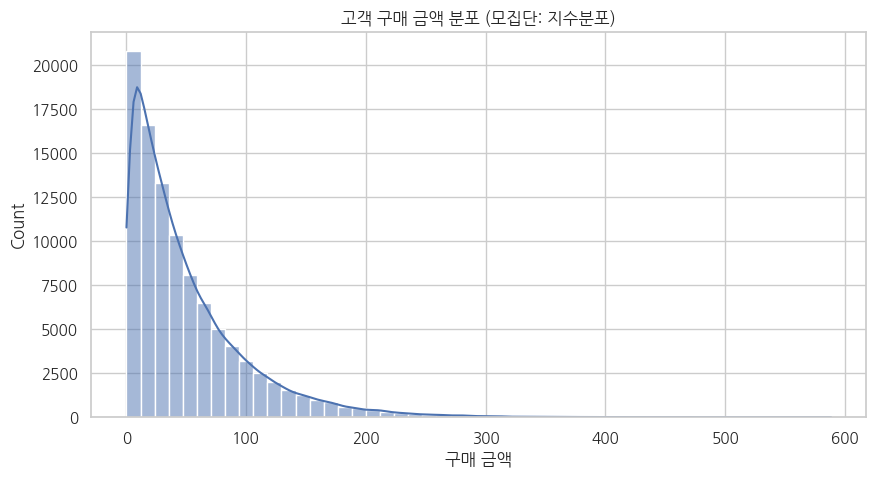

In [7]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [8]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때
sample_size = 5
means_n5 = []                                                     # 표본 평균 저장 리스트

for _ in range(1000):
    sample = np.random.choice(population, size=sample_size, replace=False)  # 무작위 5명
    means_n5.append(sample.mean())

print(f"저장된 표본 평균 개수 : {len(means_n5)}개")
print(f"처음 5개              : {np.round(means_n5[:5], 2)}")
print(f"표본 평균들의 평균    : {np.mean(means_n5):.2f}   (모평균 {population.mean():.2f})")
print(f"표본 평균들의 표준편차: {np.std(means_n5):.2f}   (이론 σ/√n = {population.std()/np.sqrt(sample_size):.2f})")

저장된 표본 평균 개수 : 1000개
처음 5개              : [26.66 92.05 45.3  47.85 65.27]
표본 평균들의 평균    : 49.41   (모평균 50.23)
표본 평균들의 표준편차: 22.43   (이론 σ/√n = 22.50)


In [9]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100
from scipy import stats

means_by_size = {5: means_n5}                     # Q1 결과(n=5)도 함께 보관

for sample_size in [30, 100]:
    means = []
    for _ in range(1000):
        sample = np.random.choice(population, size=sample_size, replace=False)
        means.append(sample.mean())
    means_by_size[sample_size] = means

# 표본 크기별 비교
print(f"{'n':>4} | {'평균들의 평균':>12} | {'흔들림(SD)':>10} | {'이론 σ/√n':>9} | {'왜도':>6}")
for n, m in means_by_size.items():
    print(f"{n:>4} | {np.mean(m):12.2f} | {np.std(m):10.2f} | "
          f"{population.std()/np.sqrt(n):9.2f} | {stats.skew(m):6.2f}")

   n |      평균들의 평균 |    흔들림(SD) |   이론 σ/√n |     왜도
   5 |        49.41 |      22.43 |     22.50 |   1.06
  30 |        50.56 |       9.00 |      9.19 |   0.38
 100 |        50.21 |       5.08 |      5.03 |   0.32


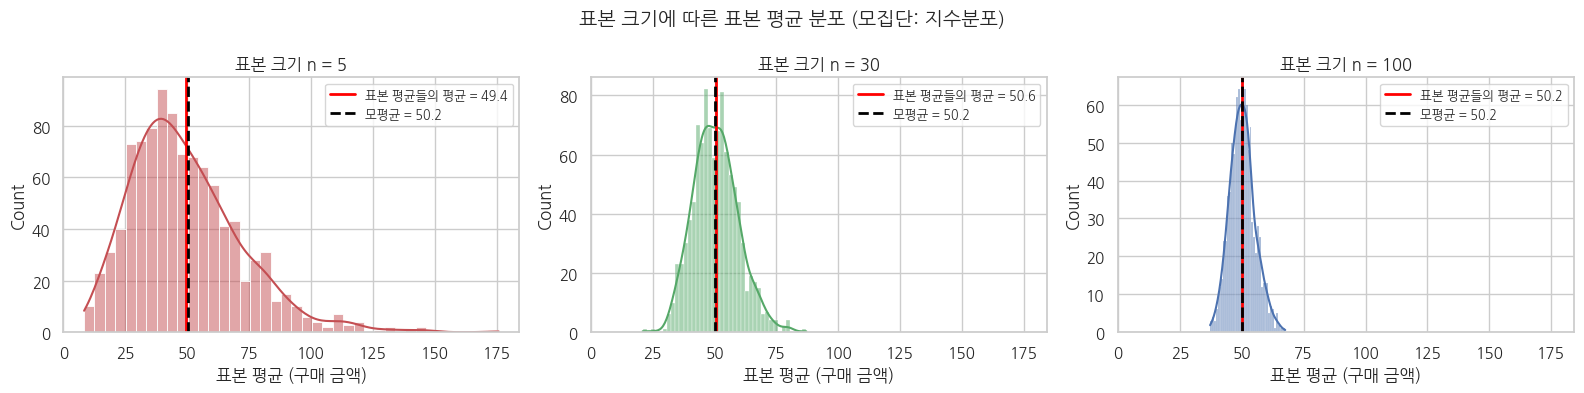

In [10]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.
pop_mean = population.mean()
colors = {5: "#C44E52", 30: "#55A868", 100: "#4C72B0"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)   # x축을 같게 → 폭 비교가 쉬움
for ax, (n, m) in zip(axes, means_by_size.items()):
    sns.histplot(m, bins=40, kde=True, color=colors[n], ax=ax)
    ax.axvline(np.mean(m), color="red", lw=2, label=f"표본 평균들의 평균 = {np.mean(m):.1f}")
    ax.axvline(pop_mean, color="black", ls="--", lw=2, label=f"모평균 = {pop_mean:.1f}")
    ax.set_title(f"표본 크기 n = {n}")
    ax.set_xlabel("표본 평균 (구매 금액)")
    ax.legend(fontsize=9)

plt.suptitle("표본 크기에 따른 표본 평균 분포 (모집단: 지수분포)", fontsize=14)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

      구분    평균  흩어짐(SD)  이론 σ/√n   왜도  Shapiro p
0   모집단  50.233      50.321        NaN  2.003        NaN
1    n = 5  49.410      22.429     22.504  1.060        0.0
2   n = 30  50.556       8.998      9.187  0.380        0.0
3  n = 100  50.212       5.077      5.032  0.317        0.0


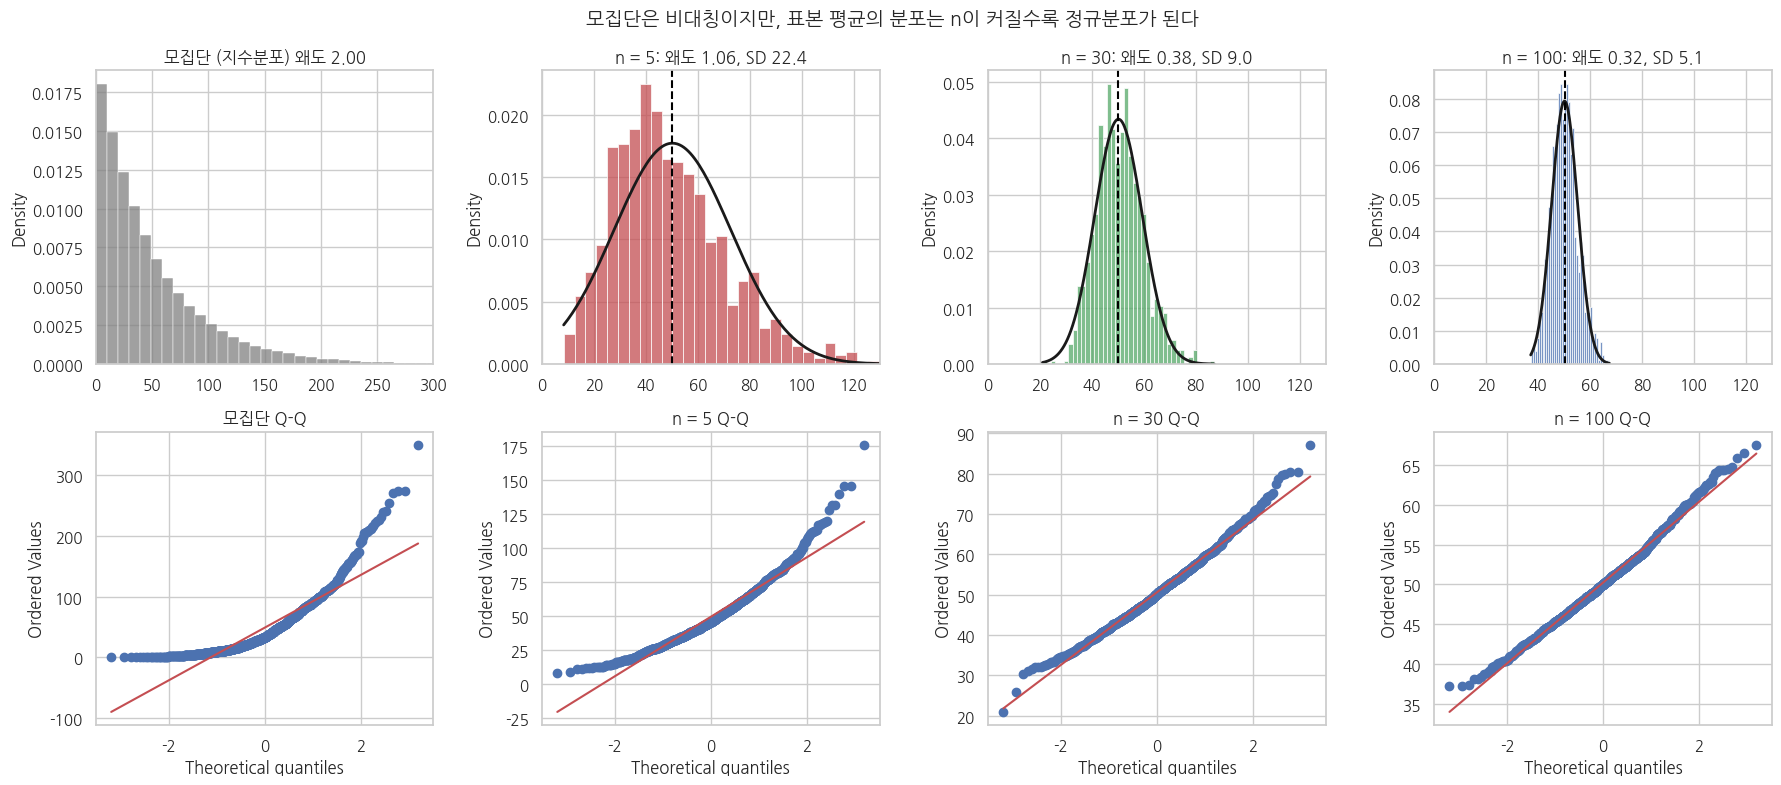

In [27]:
# ─────────────────────────────────────────────
# [문제 2] 🧠 데이터를 어떻게 읽을까요? — 중심극한정리(CLT) 확인
#   ※ 다른 문제의 변수와 섞이지 않도록 이 셀 안에서 데이터를 다시 만듭니다
# ─────────────────────────────────────────────
from scipy import stats

np.random.seed(2025)
pop2 = np.random.exponential(scale=50, size=100000)     # 문제 2 모집단 (지수분포, 평균 50)
sizes2 = [5, 30, 100]
means2 = {n: np.array([np.random.choice(pop2, n, replace=False).mean() for _ in range(1000)])
          for n in sizes2}

# ── 숫자로 요약 ──
rows = [["모집단", pop2.mean(), pop2.std(), np.nan, stats.skew(pop2), np.nan]]
for n, m in means2.items():
    rows.append([f"n = {n}", m.mean(), m.std(), pop2.std() / np.sqrt(n),
                 stats.skew(m), stats.shapiro(m).pvalue])
summary = pd.DataFrame(rows, columns=["구분", "평균", "흩어짐(SD)", "이론 σ/√n", "왜도", "Shapiro p"]).round(3)
display(summary)

# ── 그림: 위 = 히스토그램, 아래 = 정규 Q-Q plot ──
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
sns.histplot(pop2, bins=60, stat="density", color="gray", ax=ax[0, 0])
ax[0, 0].set_title(f"모집단 (지수분포) 왜도 {stats.skew(pop2):.2f}"); ax[0, 0].set_xlim(0, 300)
stats.probplot(np.random.choice(pop2, 1000), dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("모집단 Q-Q")
for j, (n, c) in enumerate(zip(sizes2, ["#C44E52", "#55A868", "#4C72B0"]), start=1):
    m = means2[n]
    sns.histplot(m, bins=40, stat="density", color=c, ax=ax[0, j])
    xs = np.linspace(m.min(), m.max(), 200)
    ax[0, j].plot(xs, stats.norm.pdf(xs, pop2.mean(), pop2.std()/np.sqrt(n)), "k-", lw=2)
    ax[0, j].axvline(pop2.mean(), color="black", ls="--")
    ax[0, j].set_title(f"n = {n}: 왜도 {stats.skew(m):.2f}, SD {m.std():.1f}")
    ax[0, j].set_xlim(0, 130)                             # 같은 x축 → 넓이 비교
    stats.probplot(m, dist="norm", plot=ax[1, j]); ax[1, j].set_title(f"n = {n} Q-Q")
plt.suptitle("모집단은 비대칭이지만, 표본 평균의 분포는 n이 커질수록 정규분포가 된다", fontsize=14)
plt.tight_layout(); plt.show()

# ▶ 질문 1. 표본 크기가 작을 때(n=5)
#    모집단(지수분포)을 닮아 오른쪽 꼬리가 긴 우편향 모양이다. 왜도가 1 안팎으로 크고,
#    Shapiro p ≈ 0으로 정규가 아니며, Q-Q plot 오른쪽 끝이 위로 휜다.
#
# ▶ 질문 2. 표본 크기가 커질수록
#    왜도가 0을 향해 줄고 Q-Q 점들이 직선에 붙으며, 종 모양으로 바뀐다.
#    검은 이론 정규곡선 N(μ, σ/√n)과도 점점 잘 겹친다. 중심(평균)은 항상 모평균 50 근처 그대로다.
#    ※ n=100도 Shapiro p는 작게 나온다: 평균 1,000개는 표본이 커서 검정이 작은 치우침(왜도 0.3)도
#      잡아내기 때문. Q-Q plot·왜도로 보면 정규에 충분히 가깝다 (Part 5 '큰 표본의 함정').
#
# ▶ 질문 3. 왜 비대칭 모집단에서 정규분포가 나오나?
#    평균은 여러 값을 '더해서' 나눈 것이다. 아주 큰 값(오른쪽 꼬리)이 하나 뽑혀도
#    나머지 평범한 값들과 섞이며 영향이 1/n로 희석되고, 큰 값과 작은 값이 서로 상쇄된다.
#    그래서 극단적인 평균은 드물어지고, 모평균 근처 값이 가장 많아지는 대칭 모양이 된다.
#    (주사위 1개는 1~6이 고르게 나오지만, 여러 개의 합은 가운데가 가장 흔한 것과 같은 원리)
#
# ▶ 질문 4. 중심극한정리를 어떻게 이해했나?
#    "모집단이 어떤 모양이든, 표본 크기가 충분히 크면 표본 평균의 분포는 정규분포에 가까워진다.
#     그 중심은 모평균 μ, 흩어짐은 σ/√n 이다."
#    → 현실 데이터가 정규가 아니어도(구매 금액처럼 치우쳐도) 평균에 대한 신뢰구간·t-test를
#      쓸 수 있는 근거가 된다. 단, 모집단이 많이 치우칠수록 더 큰 n이 필요하다
#      (이번 실험에서도 n=30에서 아직 약간의 치우침이 남아 있다).
#
# ▶ 질문 5. 표본 크기에 따른 흩어짐
#    흩어짐(SD)이 n=5 → 30 → 100으로 갈수록 크게 줄고, 이론값 σ/√n과 거의 같다.
#    n이 4배가 되면 흩어짐은 절반이 된다(√n 법칙). 표본이 클수록 평균 하나가 모평균에서
#    크게 벗어날 가능성이 줄어 → 추정이 더 정확해진다.

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

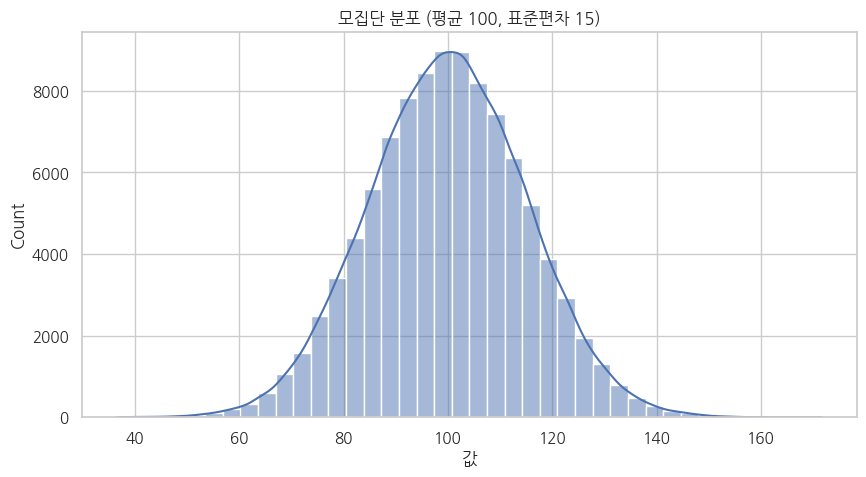

In [11]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [12]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.
sample_sizes = [10, 30, 100, 500]
std_list = []                                   # 표본 크기별 표준편차를 담을 리스트

for n in sample_sizes:
    means = []
    for _ in range(1000):
        sample = np.random.choice(population, size=n, replace=False)
        means.append(sample.mean())
    std_list.append(np.std(means))              # 표본 평균 1000개의 표준편차

# 표로 정리
result = pd.DataFrame({
    "표본 크기 n": sample_sizes,
    "표본평균 분포의 표준편차": np.round(std_list, 2),
    "이론 σ/√n": np.round([population.std() / np.sqrt(n) for n in sample_sizes], 2),
})
result

   표본 크기 n  표본평균 분포의 표준편차  이론 σ/√n
0           10                      4.66       4.75
1           30                      2.78       2.74
2          100                      1.53       1.50
3          500                      0.66       0.67


모집단 표준편차 σ = 15.03
   표본 크기 n  시뮬레이션 SD  이론 SE (σ/√n)  차이  비율 (시뮬/이론)
0           10           4.66            4.75 -0.10             0.980
1           30           2.78            2.74  0.04             1.015
2          100           1.53            1.50  0.02             1.015
3          500           0.66            0.67 -0.01             0.986


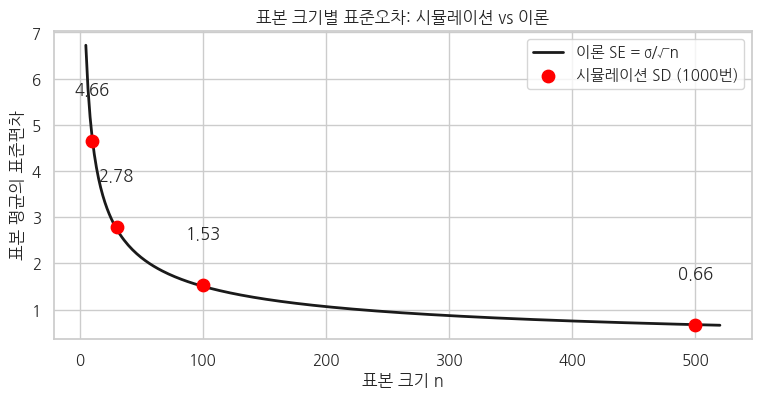

In [13]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기
sigma = population.std()                                   # 모집단 표준편차 σ
se_theory = [sigma / np.sqrt(n) for n in sample_sizes]     # 이론 SE

compare = pd.DataFrame({
    "표본 크기 n": sample_sizes,
    "시뮬레이션 SD": np.round(std_list, 2),
    "이론 SE (σ/√n)": np.round(se_theory, 2),
    "차이": np.round(np.array(std_list) - np.array(se_theory), 2),
    "비율 (시뮬/이론)": np.round(np.array(std_list) / np.array(se_theory), 3),
})
print(f"모집단 표준편차 σ = {sigma:.2f}")
display(compare)

# 그래프: 시뮬레이션 값과 이론 곡선 비교
n_line = np.linspace(5, 520, 300)
plt.figure(figsize=(9, 4))
plt.plot(n_line, sigma / np.sqrt(n_line), "k-", lw=2, label="이론 SE = σ/√n")
plt.scatter(sample_sizes, std_list, s=80, color="red", zorder=3, label="시뮬레이션 SD (1000번)")
for n, s in zip(sample_sizes, std_list):
    plt.text(n, s + 1, f"{s:.2f}", ha="center")
plt.title("표본 크기별 표준오차: 시뮬레이션 vs 이론")
plt.xlabel("표본 크기 n"); plt.ylabel("표본 평균의 표준편차")
plt.legend(); plt.show()

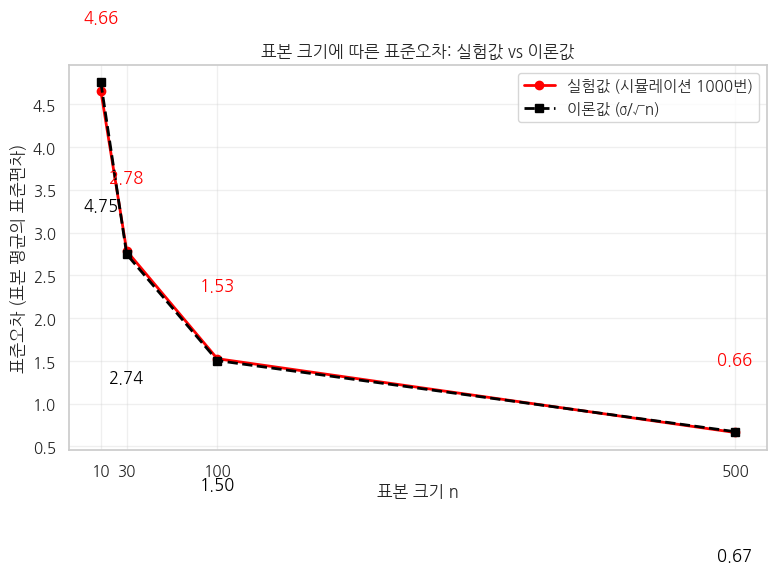

In [14]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.
plt.figure(figsize=(9, 5))
plt.plot(sample_sizes, std_list, marker="o", lw=2, color="red", label="실험값 (시뮬레이션 1000번)")
plt.plot(sample_sizes, se_theory, marker="s", lw=2, ls="--", color="black", label="이론값 (σ/√n)")

for n, s, t in zip(sample_sizes, std_list, se_theory):        # 점마다 값 표시
    plt.text(n, s + 0.8, f"{s:.2f}", ha="center", color="red")
    plt.text(n, t - 1.5, f"{t:.2f}", ha="center", color="black")

plt.xticks(sample_sizes)
plt.title("표본 크기에 따른 표준오차: 실험값 vs 이론값")
plt.xlabel("표본 크기 n")
plt.ylabel("표준오차 (표본 평균의 표준편차)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

■ 질문 1·2. 표본 크기별 표본 평균 분포
     n  최솟값  최댓값  95% 하한  95% 상한  95% 폭  왜도
0   10   86.95  116.70     89.75    109.17   19.42  0.02
1   30   91.32  111.83     93.97    105.17   11.21 -0.06
2  100   94.21  104.77     96.75    102.97    6.22 -0.13
3  500   97.62  101.86     98.59    101.20    2.61 -0.25

■ 질문 3. 실험값 vs 이론값
   n= 10: 실험   4.66  /  이론   4.75  →  비율 0.980  (오차 2.0%)
   n= 30: 실험   2.78  /  이론   2.74  →  비율 1.015  (오차 1.5%)
   n=100: 실험   1.53  /  이론   1.50  →  비율 1.015  (오차 1.5%)
   n=500: 실험   0.66  /  이론   0.67  →  비율 0.986  (오차 1.4%)

■ 질문 4. 극단값 하나(구매 300원)가 평균을 얼마나 흔드나?
   n= 10: 300원 한 명이 평균을 끌어올리는 양 ≈ (300-50)/10 =  25.00원
   n= 30: 300원 한 명이 평균을 끌어올리는 양 ≈ (300-50)/30 =   8.33원
   n=100: 300원 한 명이 평균을 끌어올리는 양 ≈ (300-50)/100 =   2.50원
   n=500: 300원 한 명이 평균을 끌어올리는 양 ≈ (300-50)/500 =   0.50원


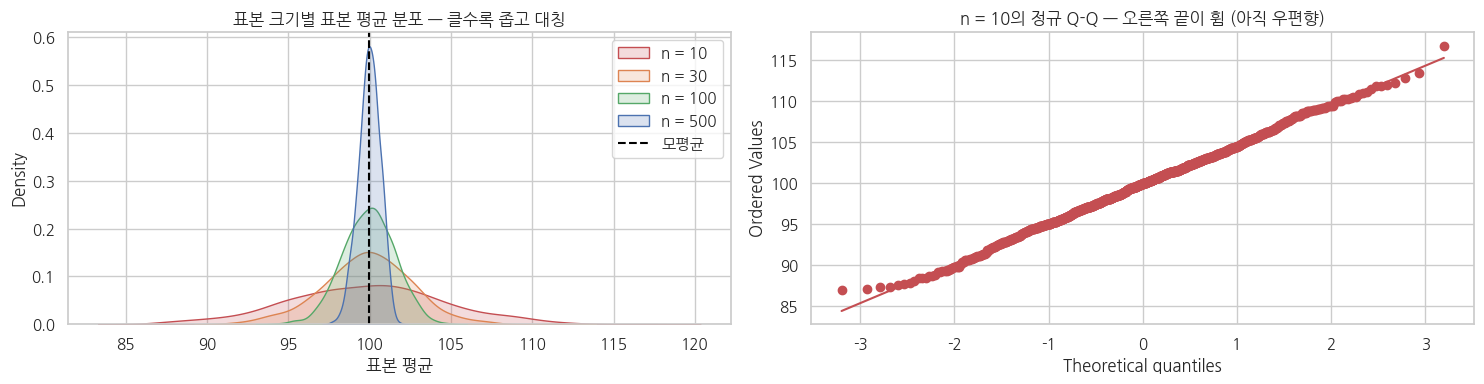

In [15]:
# ─────────────────────────────────────────────
# [문제 3] 🧠 데이터를 어떻게 읽을까요? — 네 질문을 숫자·그림으로 확인
#   ※ population, sample_sizes, std_list, se_theory 가 있다고 가정
# ─────────────────────────────────────────────
from scipy import stats

# 표본 크기별 표본 평균 1000개 다시 모으기 (분포 모양을 보려고)
means_dict = {n: np.array([np.random.choice(population, n, replace=False).mean()
                           for _ in range(1000)]) for n in sample_sizes}

# ── 질문 1·2) 표본 크기에 따라 분포 모양이 어떻게 달라지나? ──
rows = []
for n, m in means_dict.items():
    lo, hi = np.percentile(m, [2.5, 97.5])
    rows.append([n, m.min(), m.max(), lo, hi, hi - lo, stats.skew(m)])
shape = pd.DataFrame(rows, columns=["n", "최솟값", "최댓값", "95% 하한", "95% 상한", "95% 폭", "왜도"]).round(2)
print("■ 질문 1·2. 표본 크기별 표본 평균 분포")
display(shape)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for n, c in zip(sample_sizes, ["#C44E52", "#DD8452", "#55A868", "#4C72B0"]):
    sns.kdeplot(means_dict[n], ax=ax[0], color=c, fill=True, alpha=.2, label=f"n = {n}")
ax[0].axvline(population.mean(), color="black", ls="--", label="모평균")
ax[0].set_title("표본 크기별 표본 평균 분포 — 클수록 좁고 대칭"); ax[0].set_xlabel("표본 평균"); ax[0].legend()
stats.probplot(means_dict[10], dist="norm", plot=ax[1])
ax[1].get_lines()[0].set_color("#C44E52"); ax[1].set_title("n = 10의 정규 Q-Q — 오른쪽 끝이 휨 (아직 우편향)")
plt.tight_layout(); plt.show()
# ▶ 질문 1: n이 작으면(10) 분포가 넓게 퍼지고(95% 폭 약 65), 모집단(지수분포)을 닮아
#           오른쪽 꼬리가 긴 우편향이다(왜도 0.7 안팎, Q-Q 오른쪽 끝이 위로 휨).
# ▶ 질문 2: n이 커질수록 ① 폭이 좁아지고(n=500에서 약 9) ② 왜도가 0에 가까워져
#           종 모양 정규분포가 된다. 중심은 항상 모평균(약 50) 그대로다. → 중심극한정리

# ── 질문 3) 실험값과 이론값은 얼마나 비슷한가? ──
ratio = np.array(std_list) / np.array(se_theory)
print("\n■ 질문 3. 실험값 vs 이론값")
for n, s, t, r in zip(sample_sizes, std_list, se_theory, ratio):
    print(f"   n={n:3d}: 실험 {s:6.2f}  /  이론 {t:6.2f}  →  비율 {r:.3f}  (오차 {abs(r-1):.1%})")
# ▶ 모든 n에서 오차가 몇 % 이내 → 공식 σ/√n이 실제를 잘 설명한다.
#   남은 작은 차이는 1000번만 반복했기 때문에 생긴 우연한 오차다.

# ── 질문 4) 왜 n이 커질수록 표준오차가 작아지나? ──
print("\n■ 질문 4. 극단값 하나(구매 300원)가 평균을 얼마나 흔드나?")
for n in sample_sizes:
    print(f"   n={n:3d}: 300원 한 명이 평균을 끌어올리는 양 ≈ (300-50)/{n} = {(300-50)/n:6.2f}원")
# ▶ 평균은 n명의 값을 더해 n으로 나눈 것이라, 한 사람의 극단값이 평균에 주는 영향이 1/n로 줄어든다.
#   또 사람이 많을수록 높은 값과 낮은 값이 서로 상쇄될 기회가 많아진다.
#   수식으로는  Var(x̄) = Var(x₁+…+xₙ)/n² = nσ²/n² = σ²/n   →   SE = σ/√n
#   (독립인 값들의 분산은 n배로 더해지지만, n²으로 나누므로 결국 1/n만 남는다)

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

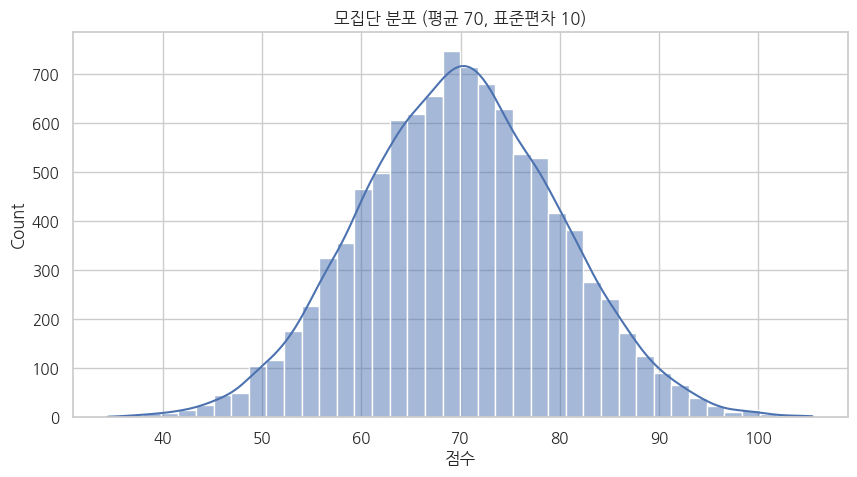

In [16]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [17]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.
n = 30
sample = np.random.choice(population, size=n, replace=False)   # 무작위 30명

sample_mean = sample.mean()              # 표본 평균 x̄
sample_std  = sample.std(ddof=1)         # 표본 표준편차 s (n-1로 나눔)
se          = sample_std / np.sqrt(n)    # 표준오차 SE = s / √n

print(f"표본 크기       : {n}명")
print(f"표본 평균       : {sample_mean:.2f}")
print(f"표본 표준편차   : {sample_std:.2f}")
print(f"표준오차 (SE)   : {se:.2f}")
print(f"\n(참고) 모평균 = {population.mean():.2f},  이론 SE = σ/√n = {population.std()/np.sqrt(n):.2f}")

표본 크기       : 30명
표본 평균       : 67.60
표본 표준편차   : 11.08
표준오차 (SE)   : 2.02

(참고) 모평균 = 69.90,  이론 SE = σ/√n = 1.83


In [18]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
from scipy import stats

sigma    = population.std()                 # 모집단 표준편차 σ (알고 있다고 가정)
se_z     = sigma / np.sqrt(n)               # 표준오차 = σ / √n
z_crit   = stats.norm.ppf(0.975)            # 95% → 양쪽 2.5%씩 → z = 1.96
margin   = z_crit * se_z                    # 오차 한계
ci_lower = sample_mean - margin
ci_upper = sample_mean + margin

print(f"표본 평균        : {sample_mean:.2f}")
print(f"모집단 표준편차 σ: {sigma:.2f}")
print(f"표준오차 σ/√n    : {se_z:.2f}")
print(f"z 임계값         : {z_crit:.2f}")
print(f"오차 한계        : ±{margin:.2f}")
print(f"95% 신뢰구간     : [{ci_lower:.2f}, {ci_upper:.2f}]")
print(f"\n모평균 {population.mean():.2f}이 구간 안에 있나? → {ci_lower <= population.mean() <= ci_upper}")

표본 평균        : 67.60
모집단 표준편차 σ: 10.01
표준오차 σ/√n    : 1.83
z 임계값         : 1.96
오차 한계        : ±3.58
95% 신뢰구간     : [64.02, 71.18]

모평균 69.90이 구간 안에 있나? → True


In [19]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
df_t     = n - 1                                # 자유도 = n - 1
se_t     = sample_std / np.sqrt(n)              # 표준오차 = s / √n  (σ 대신 s 사용)
t_crit   = stats.t.ppf(0.975, df=df_t)          # 자유도 29인 t-분포의 97.5% 지점
margin_t = t_crit * se_t
ci_lower_t = sample_mean - margin_t
ci_upper_t = sample_mean + margin_t

print(f"표본 평균        : {sample_mean:.2f}")
print(f"표본 표준편차 s  : {sample_std:.2f}")
print(f"표준오차 s/√n    : {se_t:.2f}")
print(f"자유도           : {df_t}")
print(f"t 임계값         : {t_crit:.3f}   (z였다면 1.960)")
print(f"오차 한계        : ±{margin_t:.2f}")
print(f"95% 신뢰구간     : [{ci_lower_t:.2f}, {ci_upper_t:.2f}]")
print(f"\n모평균 {population.mean():.2f}이 구간 안에 있나? → {ci_lower_t <= population.mean() <= ci_upper_t}")

# (참고) 바로 구하는 함수
print("scipy 한 줄 계산:", np.round(stats.t.interval(0.95, df=df_t, loc=sample_mean, scale=se_t), 2))

표본 평균        : 67.60
표본 표준편차 s  : 11.08
표준오차 s/√n    : 2.02
자유도           : 29
t 임계값         : 2.045   (z였다면 1.960)
오차 한계        : ±4.14
95% 신뢰구간     : [63.47, 71.74]

모평균 69.90이 구간 안에 있나? → True
scipy 한 줄 계산: [63.47 71.74]


  신뢰수준  t 임계값   하한   상한  구간 폭
0      90%      1.70  64.17  71.04     6.87
1      95%      2.05  63.47  71.74     8.27
2      99%      2.76  62.03  73.18    11.15


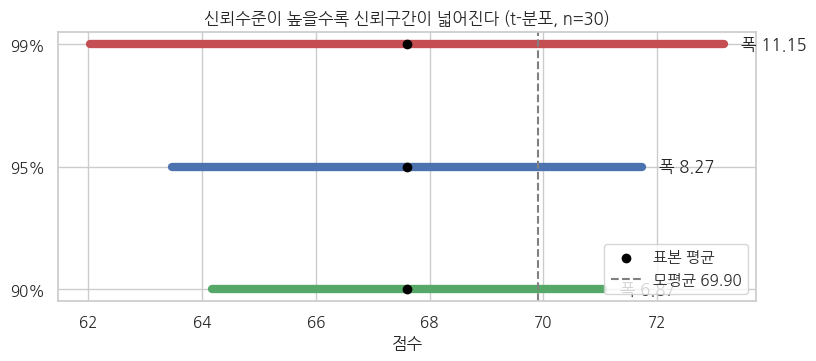

In [26]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.
from scipy import stats

# 문제 4 데이터 다시 준비 (문제 5에서 변수가 덮어써졌을 수 있으므로)
np.random.seed(2025)
pop4    = np.random.normal(loc=70, scale=10, size=10000)
n4      = 30
sample4 = np.random.choice(pop4, size=n4, replace=False)
mean4   = sample4.mean()
se4     = sample4.std(ddof=1) / np.sqrt(n4)

# 신뢰수준별 신뢰구간 (t-분포)
rows = []
for cl in [0.90, 0.95, 0.99]:                         # 비교를 위해 95%도 함께
    t_c = stats.t.ppf((1 + cl) / 2, df=n4 - 1)        # 90% → 0.95, 99% → 0.995 지점
    m   = t_c * se4
    rows.append([f"{int(cl*100)}%", t_c, mean4 - m, mean4 + m, 2 * m])

ci_table = pd.DataFrame(rows, columns=["신뢰수준", "t 임계값", "하한", "상한", "구간 폭"]).round(2)
display(ci_table)

# 시각화
plt.figure(figsize=(9, 3.5))
for i, (lab, _, lo, hi, w) in enumerate(rows):
    plt.plot([lo, hi], [i, i], lw=6, color=["#55A868", "#4C72B0", "#C44E52"][i])
    plt.text(hi + 0.3, i, f"폭 {w:.2f}", va="center")
plt.scatter([mean4] * 3, range(3), color="black", zorder=3, label="표본 평균")
plt.axvline(pop4.mean(), color="gray", ls="--", label=f"모평균 {pop4.mean():.2f}")
plt.yticks(range(3), [r[0] for r in rows])
plt.title("신뢰수준이 높을수록 신뢰구간이 넓어진다 (t-분포, n=30)")
plt.xlabel("점수"); plt.legend(loc="lower right"); plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

■ 질문 1. z vs t (95%)
   z: 67.60 ± 1.960×1.83 = [64.02, 71.18]  폭 7.16
   t: 67.60 ± 2.045×2.02 = [63.47, 71.74]  폭 8.27
   표본 크기별 t 임계값 (z = 1.960):
     n=   5 → t = 2.776
     n=  10 → t = 2.262
     n=  30 → t = 2.045
     n= 100 → t = 1.984
     n=1000 → t = 1.962

■ 질문 2. 신뢰수준별 구간 폭
    80.0%: t = 1.311  →  폭  5.30
    90.0%: t = 1.699  →  폭  6.87
    95.0%: t = 2.045  →  폭  8.27
    99.0%: t = 2.756  →  폭 11.15
    99.9%: t = 3.659  →  폭 14.80

■ 질문 3. 90% 구간 100개 중 모평균 포함: 94개

■ 질문 3. 99% 구간 100개 중 모평균 포함: 98개

■ 질문 4. 목표 만족도 65점 판단
   95% 신뢰구간 [63.47, 71.74]
   → 구간이 목표에 걸침: '달성했다/못했다' 단정 불가 → 표본 추가 수집 필요
   오차 ±2점으로 줄이려면 필요한 표본 ≈ (1.96×11.08/2)² = 118명


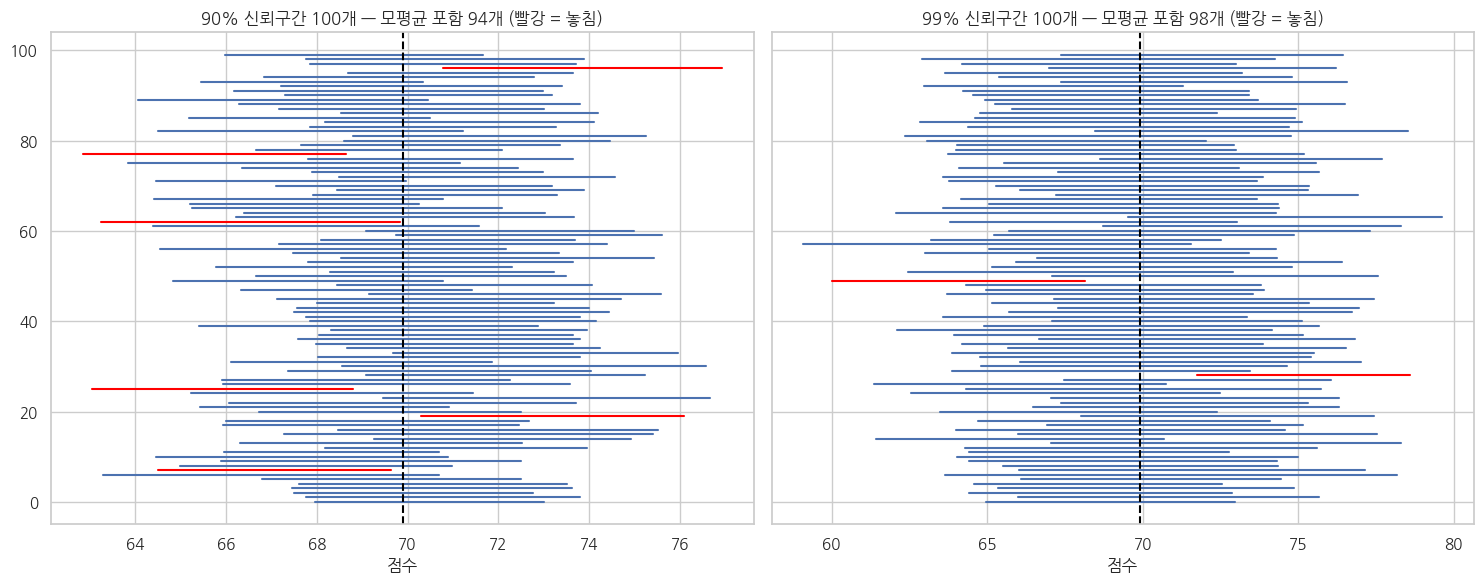

In [20]:
# ─────────────────────────────────────────────
# [문제 4] 🧠 데이터를 어떻게 읽을까요? — 네 질문을 숫자·그림으로 확인
#   ※ population, sample, sample_mean, sample_std, n 이 있다고 가정 (문제 4 Q1~Q4)
# ─────────────────────────────────────────────
from scipy import stats
mu    = population.mean()
sigma = population.std()

# ── 질문 1) z-분포 vs t-분포 신뢰구간 차이 ──
z_c = stats.norm.ppf(0.975);           se_z = sigma / np.sqrt(n)
t_c = stats.t.ppf(0.975, df=n - 1);    se_t = sample_std / np.sqrt(n)
print("■ 질문 1. z vs t (95%)")
print(f"   z: {sample_mean:.2f} ± {z_c:.3f}×{se_z:.2f} = [{sample_mean-z_c*se_z:.2f}, {sample_mean+z_c*se_z:.2f}]  폭 {2*z_c*se_z:.2f}")
print(f"   t: {sample_mean:.2f} ± {t_c:.3f}×{se_t:.2f} = [{sample_mean-t_c*se_t:.2f}, {sample_mean+t_c*se_t:.2f}]  폭 {2*t_c*se_t:.2f}")
print("   표본 크기별 t 임계값 (z = 1.960):")
for k in [5, 10, 30, 100, 1000]:
    print(f"     n={k:4d} → t = {stats.t.ppf(0.975, k-1):.3f}")
# ▶ t 구간이 조금 더 넓다. 이유 두 가지:
#   ① σ를 모르고 s로 '추정'한 불확실성까지 반영 → t 임계값(2.045)이 z(1.960)보다 큼
#   ② 이번 표본은 s(11.08)가 σ(10)보다 우연히 커서 표준오차도 커졌다
#   n이 커지면 t → z 로 수렴해 차이가 거의 사라진다. 차이는 '작은 표본'에서 중요하다.

# ── 질문 2) 신뢰수준이 높아지면 폭은? 왜? ──
print("\n■ 질문 2. 신뢰수준별 구간 폭")
for cl in [0.80, 0.90, 0.95, 0.99, 0.999]:
    tc = stats.t.ppf((1 + cl) / 2, n - 1)
    print(f"   {cl:6.1%}: t = {tc:.3f}  →  폭 {2*tc*se_t:5.2f}")
# ▶ 신뢰수준↑ → 폭↑. "더 확실히 모평균을 잡겠다" = 양 끝에 남기는 확률(α)을 줄이겠다는 뜻이라
#   분포의 더 먼 꼬리까지 포함해야 하고, 임계값이 커져 구간이 넓어진다.
#   (100% 확신하려면 구간이 -∞~+∞ 가 되어 아무 정보도 없다)

# ── 질문 3) 넓은 구간은 좋은가 나쁜가? → 100번 반복 실험으로 확인 ──
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for j, cl in enumerate([0.90, 0.99]):
    hit = 0
    tc = stats.t.ppf((1 + cl) / 2, n - 1)
    for i in range(100):
        s = rng.choice(population, n, replace=False)
        m = tc * s.std(ddof=1) / np.sqrt(n)
        ok = (s.mean() - m <= mu <= s.mean() + m); hit += ok
        ax[j].plot([s.mean() - m, s.mean() + m], [i, i], color="#4C72B0" if ok else "red", lw=1.5)
    ax[j].axvline(mu, color="black", ls="--")
    ax[j].set_title(f"{cl:.0%} 신뢰구간 100개 — 모평균 포함 {hit}개 (빨강 = 놓침)")
    ax[j].set_xlabel("점수"); print(f"\n■ 질문 3. {cl:.0%} 구간 100개 중 모평균 포함: {hit}개")
plt.tight_layout(); plt.show()
# ▶ 넓은 구간은 '확실하지만 덜 쓸모 있고', 좁은 구간은 '쓸모 있지만 틀릴 위험이 크다'.
#   99%는 거의 다 맞히지만 구간이 길어 "62~73점" 같은 막연한 결론이 되고,
#   90%는 구간이 짧아 구체적이지만 10번 중 1번꼴로 빗나간다.
#   → 좋고 나쁨이 아니라 '목적'에 따라 고른다. 넓은데 정밀하고 싶으면 n을 늘린다.

# ── 질문 4) 고객 만족도라면 마케팅에 어떻게 쓸까? ──
target = 65                                     # 예: 회사 목표 만족도
lo95, hi95 = sample_mean - t_c*se_t, sample_mean + t_c*se_t
print(f"\n■ 질문 4. 목표 만족도 {target}점 판단")
print(f"   95% 신뢰구간 [{lo95:.2f}, {hi95:.2f}]")
if lo95 > target:   print("   → 하한도 목표 이상: 목표 달성이라고 자신 있게 보고 가능")
elif hi95 < target: print("   → 상한도 목표 미만: 개선 캠페인 필요")
else:               print("   → 구간이 목표에 걸침: '달성했다/못했다' 단정 불가 → 표본 추가 수집 필요")

E = 2                                           # 원하는 오차 한계 ±2점
n_need = int(np.ceil((stats.norm.ppf(0.975) * sample_std / E) ** 2))
print(f"   오차 ±{E}점으로 줄이려면 필요한 표본 ≈ (1.96×{sample_std:.2f}/{E})² = {n_need}명")
# ▶ 활용 예시
#   1) 목표 달성 판단: 평균 하나(67.6)가 아니라 '하한'이 목표를 넘는지로 판단 → 과신 방지
#   2) 캠페인 전후 비교: 두 기간의 신뢰구간이 크게 겹치면 "효과가 있다"고 단정하지 않는다
#   3) 세그먼트 비교: 연령·채널별 구간을 그려, 확실히 낮은 집단부터 우선 개선
#   4) 조사 예산: 원하는 정밀도(±2점)에 필요한 표본 수를 미리 계산해 설문 규모 결정
#   5) 보고서 문장: "만족도 67.6점 (95% CI 63.5~71.7, n=30)"처럼 불확실성을 함께 보고

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

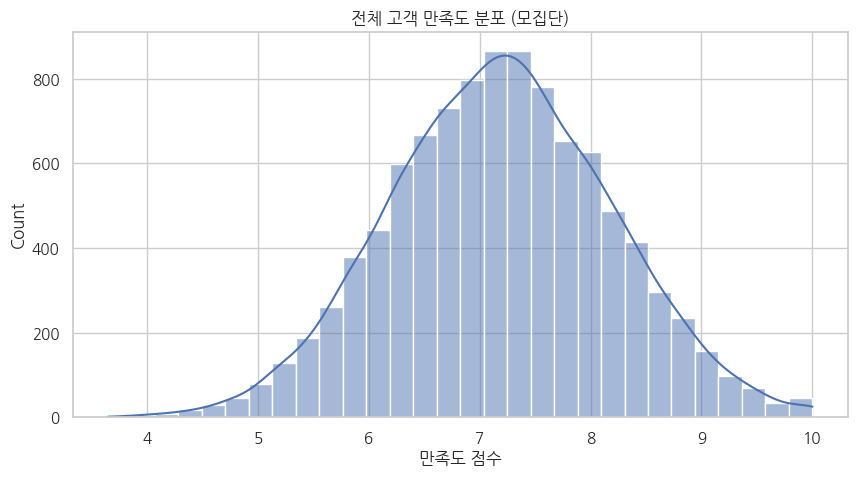

In [21]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [22]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
n = 40
sample = np.random.choice(population, size=n, replace=False)   # 무작위 40명

sample_mean = sample.mean()           # 표본 평균
sample_std  = sample.std(ddof=1)      # 표본 표준편차 (n-1로 나눔)

print(f"표본 크기     : {n}명")
print(f"표본 평균     : {sample_mean:.3f}")
print(f"표본 표준편차 : {sample_std:.3f}")
print(f"\n(참고) 모평균 = {population.mean():.3f},  모표준편차 = {population.std():.3f}")

표본 크기     : 40명
표본 평균     : 7.144
표본 표준편차 : 1.099

(참고) 모평균 = 7.190,  모표준편차 = 0.998


In [23]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
from scipy import stats

se       = sample_std / np.sqrt(n)                 # 표준오차 SE = s / √n
t_crit   = stats.t.ppf(0.975, df=n - 1)            # 자유도 39, 95% 양측
margin   = t_crit * se                             # 오차 한계
ci_lower = sample_mean - margin
ci_upper = sample_mean + margin

print(f"표준오차 (SE)  : {se:.3f}")
print(f"자유도         : {n - 1}")
print(f"t 임계값       : {t_crit:.3f}")
print(f"오차 한계      : ±{margin:.3f}")
print(f"95% 신뢰구간   : [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"\n모평균 {population.mean():.3f}이 구간 안에 있나? → {ci_lower <= population.mean() <= ci_upper}")

표준오차 (SE)  : 0.174
자유도         : 39
t 임계값       : 2.023
오차 한계      : ±0.351
95% 신뢰구간   : [6.793, 7.496]

모평균 7.190이 구간 안에 있나? → True


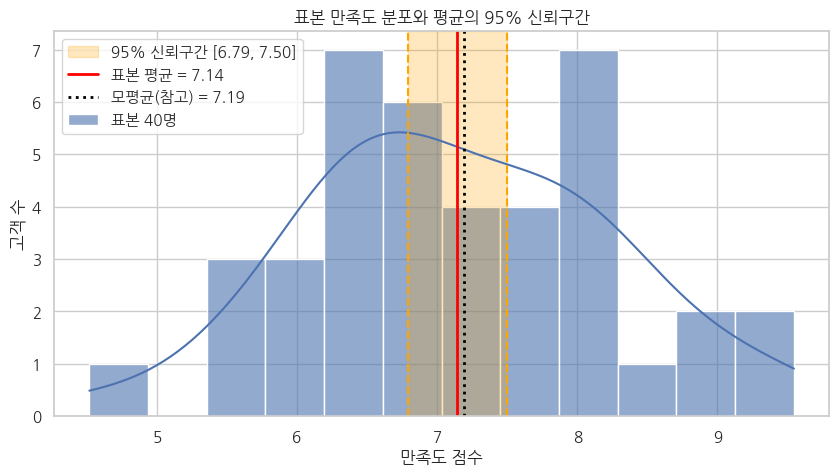

In [28]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
from scipy import stats

# ── 문제 5 데이터 다시 준비 (다른 문제에서 변수가 덮어써졌을 수 있으므로) ──
np.random.seed(2025)
pop5 = np.clip(np.random.normal(loc=7.2, scale=1.0, size=10000), 1, 10)   # 모집단
n5 = 40
sample5 = np.random.choice(pop5, size=n5, replace=False)                 # 표본 40명

mean5 = sample5.mean()                                   # 표본 평균
se5   = sample5.std(ddof=1) / np.sqrt(n5)                # 표준오차
t5    = stats.t.ppf(0.975, df=n5 - 1)                    # t 임계값
ci5_lower, ci5_upper = mean5 - t5 * se5, mean5 + t5 * se5   # 95% 신뢰구간

# ── 시각화 ──
plt.figure(figsize=(10, 5))
sns.histplot(sample5, bins=12, kde=True, color="#4C72B0", alpha=0.6, label=f"표본 {n5}명")
plt.axvspan(ci5_lower, ci5_upper, color="orange", alpha=0.25,
            label=f"95% 신뢰구간 [{ci5_lower:.2f}, {ci5_upper:.2f}]")
plt.axvline(mean5, color="red", lw=2, label=f"표본 평균 = {mean5:.2f}")
plt.axvline(ci5_lower, color="orange", ls="--", lw=1.5)
plt.axvline(ci5_upper, color="orange", ls="--", lw=1.5)
plt.axvline(pop5.mean(), color="black", ls=":", lw=2, label=f"모평균(참고) = {pop5.mean():.2f}")

plt.title("표본 만족도 분포와 평균의 95% 신뢰구간")
plt.xlabel("만족도 점수")
plt.ylabel("고객 수")
plt.legend(loc="upper left")
plt.show()

In [24]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?

# ── 의견의 근거가 되는 숫자 ──
low_share  = np.mean(sample < 6)       # 불만족 고객(6점 미만) 비율
high_share = np.mean(sample >= 8)      # 충성 고객(8점 이상) 비율
n_need = int(np.ceil((stats.norm.ppf(0.975) * sample_std / 0.2) ** 2))   # 오차 ±0.2점에 필요한 표본

print(f"평균 만족도 {sample_mean:.2f}점, 95% 신뢰구간 [{ci_lower:.2f}, {ci_upper:.2f}]")
print(f"불만족(6점 미만) {low_share:.0%}  /  충성(8점 이상) {high_share:.0%}")
print(f"오차를 ±0.2점으로 줄이려면 필요한 표본 ≈ {n_need}명")

# ── 의견 ──
# 1) 현재 수준 진단
#    - 평균 만족도는 95% 신뢰수준에서 약 6.8~7.5점. 하한(6.8)도 '보통 이상'이므로
#      "고객 전반이 대체로 만족한다"는 결론은 신뢰할 수 있다.
#    - 하지만 상한(7.5)이 8점에 못 미쳐 "매우 만족" 수준이라고 말할 근거는 없다.
#      → 마케팅 문구에 "고객 만족도 최상위" 같은 과장 표현은 피한다.
#
# 2) 목표 설정과 판단 기준
#    - 예: 목표가 7점이면 구간이 7점에 걸쳐 있어 '달성' 단정 불가 → 평균(7.14)만 보고 보고하지 않는다.
#    - 목표가 6.5점이면 하한 6.8 > 6.5 이므로 '달성'이라고 자신 있게 보고 가능.
#    - 원칙: 평균이 아니라 '신뢰구간 하한'이 목표를 넘는지로 성공 여부를 판단한다.
#
# 3) 고객군별 전략 (평균 뒤에 숨은 분포를 함께 본다)
#    - 불만족 고객(약 10%): 이탈 위험군 → 개별 연락, 불만 원인 설문, 보상 쿠폰으로 회복 시도
#    - 충성 고객(약 30%): 추천 리워드·리뷰 이벤트로 입소문 확산에 활용
#    - 중간 고객(나머지): 배송·응대 등 개선 포인트를 찾아 '만족 → 충성'으로 끌어올리기
#
# 4) 캠페인 효과 검증 계획
#    - 개선 캠페인 전후로 같은 방법의 신뢰구간을 계산해 비교한다.
#    - 두 구간이 크게 겹치면 "효과가 있다"고 단정하지 않는다 (다음 시간 t-test로 정식 검정).
#
# 5) 조사 설계 개선
#    - 현재

평균 만족도 7.14점, 95% 신뢰구간 [6.79, 7.50]
불만족(6점 미만) 10%  /  충성(8점 이상) 30%
오차를 ±0.2점으로 줄이려면 필요한 표본 ≈ 116명


**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [25]:
# ─────────────────────────────────────────────
# [문제 5] 🧠 데이터를 어떻게 읽을까요? — 네 질문을 숫자로 확인
#   ※ population, sample, n, sample_mean, sample_std, se, ci_lower, ci_upper 가 있다고 가정
# ─────────────────────────────────────────────
from scipy import stats
pop_mean = population.mean()

# ── 질문 1) 신뢰구간은 몇 점에서 몇 점? ──
print("■ 질문 1. 95% 신뢰구간")
print(f"   {ci_lower:.2f}점 ~ {ci_upper:.2f}점  (표본 평균 {sample_mean:.2f} ± {ci_upper - sample_mean:.2f})")
# ▶ 평균 만족도는 약 6.8 ~ 7.5점 사이일 것으로 추정된다.

# ── 질문 2) 모평균을 포함하나? ──
inside = ci_lower <= pop_mean <= ci_upper
print(f"\n■ 질문 2. 모평균 {pop_mean:.2f}점 포함 여부 → {inside}")
# ▶ 포함한다. 단, 현실에선 모평균을 모르므로 '이번 구간이 맞혔는지'는 확인할 수 없다.
#   우리가 아는 건 "이 방법으로 만든 구간의 95%가 모평균을 포함한다"는 사실뿐이다.

# ── 질문 3) 만족도가 충분히 높다고 말할 수 있나? ──
print("\n■ 질문 3. 기준점별 판단")
for target in [6.5, 7.0, 8.0]:
    if ci_lower > target:   verdict = "하한도 기준 이상 → '충분히 높다'고 말할 수 있음"
    elif ci_upper < target: verdict = "상한도 기준 미만 → '높다'고 말할 수 없음 (개선 필요)"
    else:                   verdict = "구간이 기준에 걸침 → 판단 보류 (표본 추가 필요)"
    print(f"   기준 {target}점: {verdict}")
# ▶ '충분히 높다'는 기준에 따라 달라진다.
#   - 6.5점 기준: 하한 6.8 > 6.5 → 충분히 높다고 말할 수 있다.
#   - 7.0점 기준: 구간이 7점에 걸쳐 있어 단정할 수 없다 (평균 7.14만 보고 '달성'이라 하면 과신).
#   - 8.0점 기준: 상한 7.5 < 8 → '매우 만족' 수준은 아니다.
#   → 기준을 먼저 정하고, 평균이 아니라 신뢰구간 전체로 판단해야 한다.

# ── 질문 4) 구간이 넓다면 왜? 어떻게 개선? ──
#   구간 폭 = 2 × t × s / √n  → 폭을 키우는 원인은 세 가지
print("\n■ 질문 4. 구간 폭을 결정하는 세 요인")
def width(n_, s_=sample_std, cl=0.95):
    return 2 * stats.t.ppf((1 + cl) / 2, n_ - 1) * s_ / np.sqrt(n_)

print(f"   현재 (n={n}, s={sample_std:.2f}, 95%) 폭 = {width(n):.3f}")
print("   ① 표본 크기를 늘리면:")
for k in [40, 100, 200, 400]:
    print(f"        n={k:3d} → 폭 {width(k):.3f}")
print("   ② 응답 편차(s)가 줄면 (질문 문항 개선 등):")
for s_ in [1.1, 0.8, 0.5]:
    print(f"        s={s_:.1f} → 폭 {width(n, s_):.3f}")
print("   ③ 신뢰수준을 낮추면:")
for cl in [0.99, 0.95, 0.90]:
    print(f"        {cl:.0%} → 폭 {width(n, cl=cl):.3f}")
# ▶ 이유:  ① 표본이 적다(n↓)  ② 고객 응답이 제각각이다(s↑)  ③ 너무 높은 확신을 요구한다(신뢰수준↑)
# ▶ 개선:
#   ① 표본 크기 늘리기 — 가장 확실한 방법. 단, 폭은 √n에 비례해 줄어 폭을 절반으로 하려면 4배 필요.
#   ② 편차 줄이기 — 모호한 설문 문항 정비, 비슷한 고객끼리 나눠(층화) 조사.
#   ③ 신뢰수준 조정 — 99% → 95%로 낮추면 좁아지지만, 틀릴 위험이 커지는 trade-off.
#   ※ 무작위 추출이 아니라 편향된 표본이라면 폭과 상관없이 결과 자체가 틀릴 수 있으니 추출 방식도 점검.

■ 질문 1. 95% 신뢰구간
   6.79점 ~ 7.50점  (표본 평균 7.14 ± 0.35)

■ 질문 2. 모평균 7.19점 포함 여부 → True

■ 질문 3. 기준점별 판단
   기준 6.5점: 하한도 기준 이상 → '충분히 높다'고 말할 수 있음
   기준 7.0점: 구간이 기준에 걸침 → 판단 보류 (표본 추가 필요)
   기준 8.0점: 상한도 기준 미만 → '높다'고 말할 수 없음 (개선 필요)

■ 질문 4. 구간 폭을 결정하는 세 요인
   현재 (n=40, s=1.10, 95%) 폭 = 0.703
   ① 표본 크기를 늘리면:
        n= 40 → 폭 0.703
        n=100 → 폭 0.436
        n=200 → 폭 0.306
        n=400 → 폭 0.216
   ② 응답 편차(s)가 줄면 (질문 문항 개선 등):
        s=1.1 → 폭 0.704
        s=0.8 → 폭 0.512
        s=0.5 → 폭 0.320
   ③ 신뢰수준을 낮추면:
        99% → 폭 0.941
        95% → 폭 0.703
        90% → 폭 0.585
